
# Exploración del mundo de los perfumes

Un análisis de los datos de Fragrantica para descubrir cuáles son los perfumes más populares, qué aromas predominan y qué diferencias existen entre las fragancias masculinas y femeninas.


***

### 1. Objetivo

El objetivo de este proyecto es explorar las características de los perfumes disponibles en el dataset y detectar posibles diferencias entre las fragancias masculinas, femeninas y unisex.

También se investigará la relación entre los perfiles olfativos y el género al que se dirige cada perfume, así como el país de origen de las fragancias más populares.

***


### 2. Hipótesis

**H1. Los perfumes femeninos dominan el catálogo.** El mercado de perfumería históricamente ha tenido más variedad en la gama femenina. Si el catálogo refleja eso, podemos medirlo con un simple conteo por departamento.

**H2. Los perfiles olfativos difieren por departamento: los masculinos son más amaderados y especiados; los femeninos, más florales y frutales.** Las fragancias suelen asociarse con determinados perfiles olfativos según el público al que van dirigidas. Investigaremos si estas diferencias se reflejan en los acordes principales (mainaccord1) y cuáles predominan en cada categoría.

**H3. Los perfumes unisex presentan perfiles olfativos más similares a los masculinos que a los femeninos.**
Muchos unisex son reformulaciones de fragancias masculinas o comparten sus notas dominantes (amaderadas, cítricas, ambaradas). Contrastar esta hipótesis añade profundidad al análisis.

**H4. Los diez perfumes más populares son de origen francés.**
Francia ocupa un lugar destacado en la historia de la perfumería y alberga algunas de las marcas más reconocidas internacionalmente. Investigaremos si este protagonismo se refleja en nuestro dataset, identificando los diez perfumes con mayor número de valoraciones (Rating Count) y analizando sus países de origen.


***


### 3. Importación

Se utiliza el dataset previamente preparado en limpieza.ipynb, donde se han seleccionado las variables relevantes y corregido las inconsistencias detectadas.


In [77]:
import pandas as pd
import matplotlib.pyplot as plt

***


### 4. Descripción general

Antes de contrastar las hipótesis, se examinan las dimensiones del conjunto de datos y las variables disponibles.


In [46]:
df = pd.read_csv("../data/perfumes_limpio.csv")
df.head()

,Perfume,Brand,Country,Gender,Rating Count,Top,Middle,Base,mainaccord1,mainaccord2,mainaccord3,mainaccord4,mainaccord5
0,accento-overdose-pride-edition,xerjoff,Italy,unisex,201,"fruity notes, aldehydes, green notes","bulgarian rose, egyptian jasmine, lily-of-the-...","eucalyptus, pine",rose,woody,fruity,aromatic,floral
1,classique-pride-2024,jean-paul-gaultier,France,women,70,"yuzu, citruses","orange blossom, neroli","musk, blonde woods",citrus,white floral,sweet,fresh,musky
2,classique-pride-2023,jean-paul-gaultier,France,unisex,285,"blood orange, yuzu","neroli, orange blossom","musk, white woods",citrus,white floral,sweet,fresh spicy,musky
3,pride-edition-man,bruno-banani,Germany,men,59,"guarana, grapefruit, red apple","walnut, lavender, guava","vetiver, benzoin, amber",fruity,nutty,woody,tropical,NaN
4,le-male-pride-collector,jean-paul-gaultier,France,men,632,"mint, lavender, cardamom, artemisia, bergamot","caraway, cinnamon, orange blossom","vanilla, sandalwood, amber, cedar, tonka bean",aromatic,warm spicy,fresh spicy,cinnamon,vanilla


In [47]:
# dimensiones y tipos de datos
print(df.shape)
df.dtypes

(24063, 13)


Perfume           str
Brand             str
Country           str
Gender            str
Rating Count    int64
Top               str
Middle            str
Base              str
mainaccord1       str
mainaccord2       str
mainaccord3       str
mainaccord4       str
mainaccord5       str
dtype: object

In [48]:
# valores nulos por columna
df.isnull().sum()

Perfume           0
Brand             0
Country           0
Gender            0
Rating Count      0
Top               0
Middle            0
Base              0
mainaccord1       0
mainaccord2      13
mainaccord3     114
mainaccord4     388
mainaccord5     981
dtype: int64

In [49]:
# estadisticas basicas
df.describe()

,Rating Count
count,24063.000000
mean,501.396542
std,1429.484690
min,26.000000
25%,56.000000
50%,127.000000
75%,360.000000
max,29858.000000


***

### 5. Análisis de hipótesis
Aquí se analizan los datos obtenidos para comprobar si los hipótesis iniciales se cumplen o si los resultados muestran tendencias diferentes a las esperadas.

***

### H1. Distribución de perfumes por género

**Hipótesis 1: Los perfumes femeninos dominan el catálogo.**

Para comprobarlo, se analiza la cantidad y el porcentaje de perfumes clasificados como Women, Men y Unisex.


In [50]:
# contar perfumes, numero de perfumes por genero
generos = df["Gender"].value_counts()
generos

Gender
women     11376
unisex     7698
men        4989
Name: count, dtype: int64


Visualización de la distribución por género:

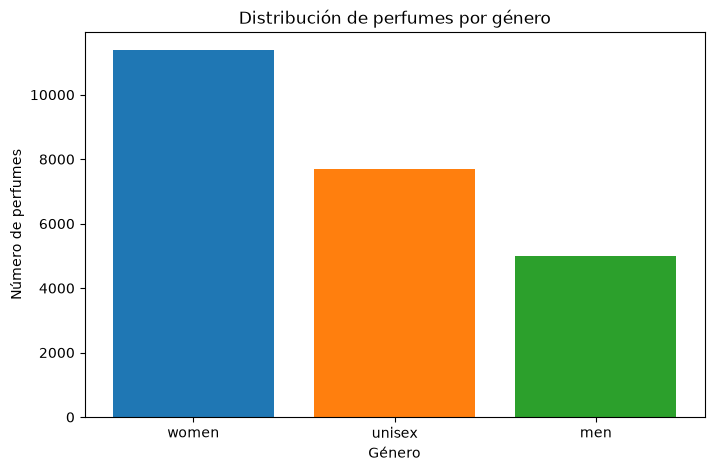

In [51]:
# distribución de perfumes por genero
plt.figure(figsize=(8, 5))

plt.bar(generos.index, generos.values, color=plt.cm.tab10.colors)

plt.title("Distribución de perfumes por género")
plt.xlabel("Género")
plt.ylabel("Número de perfumes")

plt.show()

In [52]:
# calcular porcentajes, porcentaje de perfumes por genero
porcentajes = df["Gender"].value_counts(normalize=True) * 100

porcentajes.round(2)

Gender
women     47.28
unisex    31.99
men       20.73
Name: proportion, dtype: float64

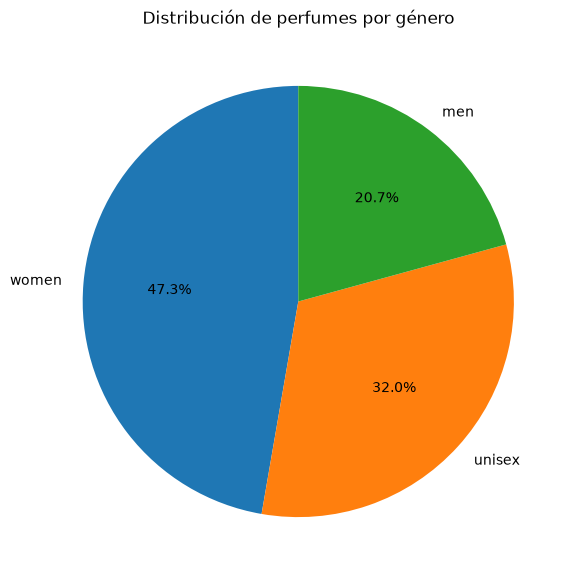

In [53]:
generos = df["Gender"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    generos,
    labels=generos.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de perfumes por género")
plt.show()


#### Conclusión de H1

**Hipótesis confirmada:** los perfumes femeninos constituyen la categoría más numerosa del catálogo analizado.

***


### H2. Diferencias olfativas entre perfumes masculinos y femeninos

**Hipótesis 2:** Los perfumes masculinos presentan principalmente acordes amaderados y especiados, mientras que los femeninos destacan por sus acordes florales y frutales.

Para comprobarlo, se analiza los acordes principales de los perfumes masculinos y femeninos, identificando los más frecuentes en cada categoría.


In [73]:
# seleccionar perfumes por genero
hombres = df[df["Gender"] == "men"]
mujeres = df[df["Gender"] == "women"]

In [81]:
# top 10 acordes masculinos
acordes_hombres = hombres["mainaccord1"].value_counts().head(10)
print(acordes_hombres)

# top 10 acordes femeninos
acordes_mujeres = mujeres["mainaccord1"].value_counts().head(10)
print(acordes_mujeres)

mainaccord1
aromatic       1059
woody           978
citrus          883
warm spicy      443
fresh spicy     348
amber           266
vanilla         147
fruity          128
green           107
leather          74
Name: count, dtype: int64
mainaccord1
fruity          1736
white floral    1505
floral          1416
citrus          1323
woody            833
sweet            828
vanilla          564
powdery          521
rose             517
amber            337
Name: count, dtype: int64


Visualización de los 10 acordes principales por género:

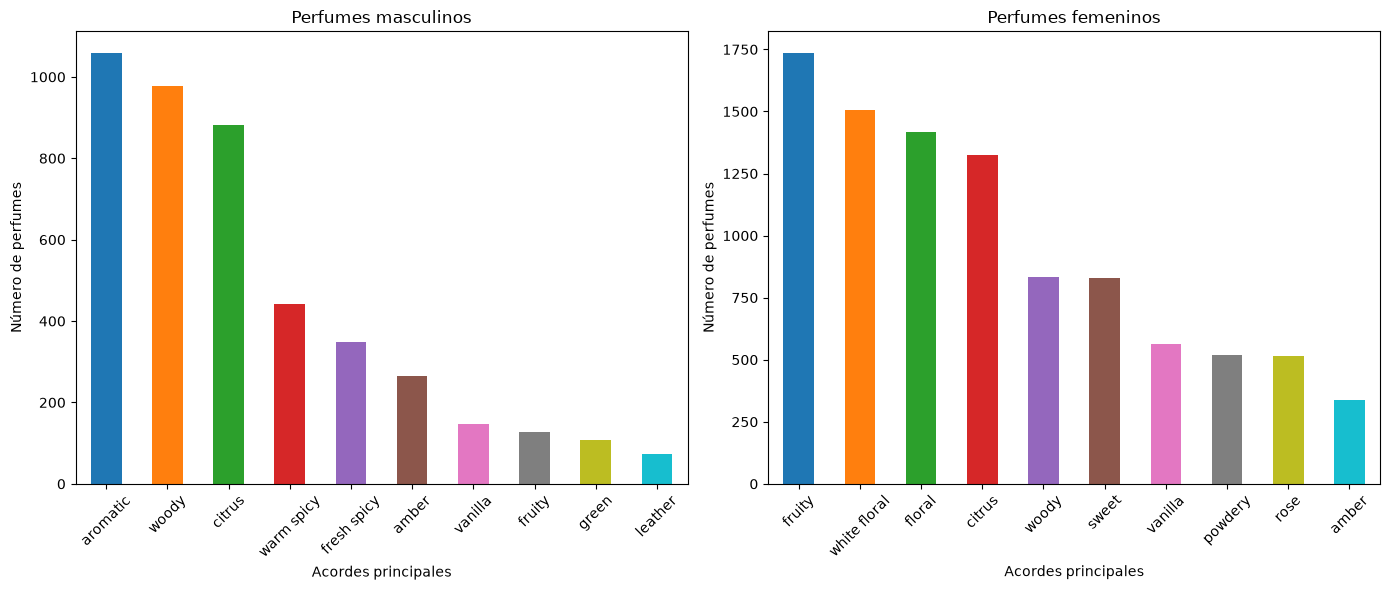

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# perfumes masculinos
acordes_hombres.plot.bar(ax=axes[0], color=plt.cm.tab10.colors)
axes[0].set_title("Perfumes masculinos")
axes[0].set_xlabel("Acordes principales")
axes[0].set_ylabel("Número de perfumes")
axes[0].tick_params(axis="x", rotation=45)

# perfumes femeninos
acordes_mujeres.plot.bar(ax=axes[1],  color=plt.cm.tab10.colors)
axes[1].set_title("Perfumes femeninos")
axes[1].set_xlabel("Acordes principales")
axes[1].set_ylabel("Número de perfumes")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Para comparar los perfiles olfativos de ambos géneros, se calcula la frecuencia relativa de cada acorde respecto al total de perfumes de su categoría.

In [57]:
# porcentajes de los 10 acordes principales
porcentajes_hombres = hombres["mainaccord1"].value_counts(normalize=True).head(10) * 100
porcentajes_mujeres = mujeres["mainaccord1"].value_counts(normalize=True).head(10) * 100

print("hombres")
print(porcentajes_hombres.round(2))

print("\nmujeres")
print(porcentajes_mujeres.round(2))

hombres
mainaccord1
aromatic       21.23
woody          19.60
citrus         17.70
warm spicy      8.88
fresh spicy     6.98
amber           5.33
vanilla         2.95
fruity          2.57
green           2.14
leather         1.48
Name: proportion, dtype: float64

mujeres
mainaccord1
fruity          15.26
white floral    13.23
floral          12.45
citrus          11.63
woody            7.32
sweet            7.28
vanilla          4.96
powdery          4.58
rose             4.54
amber            2.96
Name: proportion, dtype: float64


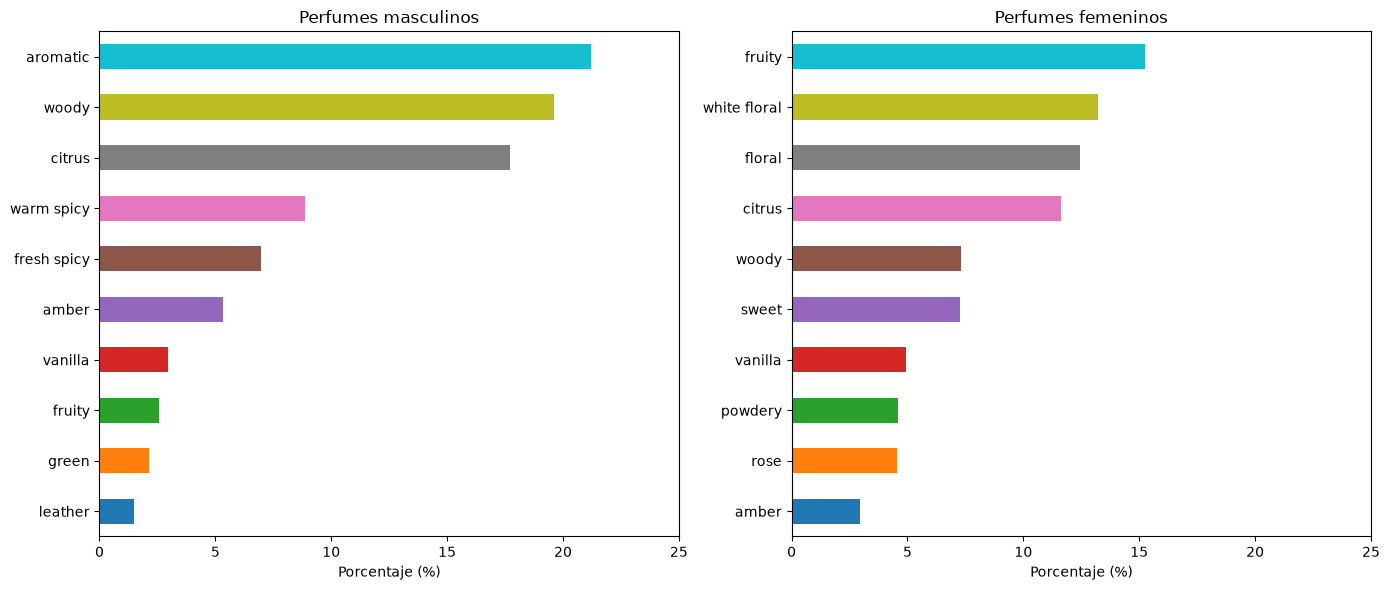

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# perfumes masculinos
porcentajes_hombres.sort_values().plot.barh(
    ax=axes[0], color=plt.cm.tab10.colors
)

axes[0].set_title("Perfumes masculinos")
axes[0].set_xlabel("Porcentaje (%)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 25)

# perfumes femeninos
porcentajes_mujeres.sort_values().plot.barh(
    ax=axes[1], color=plt.cm.tab10.colors
)

axes[1].set_title("Perfumes femeninos")
axes[1].set_xlabel("Porcentaje (%)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 25)

plt.tight_layout()
plt.show()


Se muestra los diez acordes más frecuentes de los perfumes masculinos y femeninos. El resto de los acordes se agrupa en la categoría "Otros":

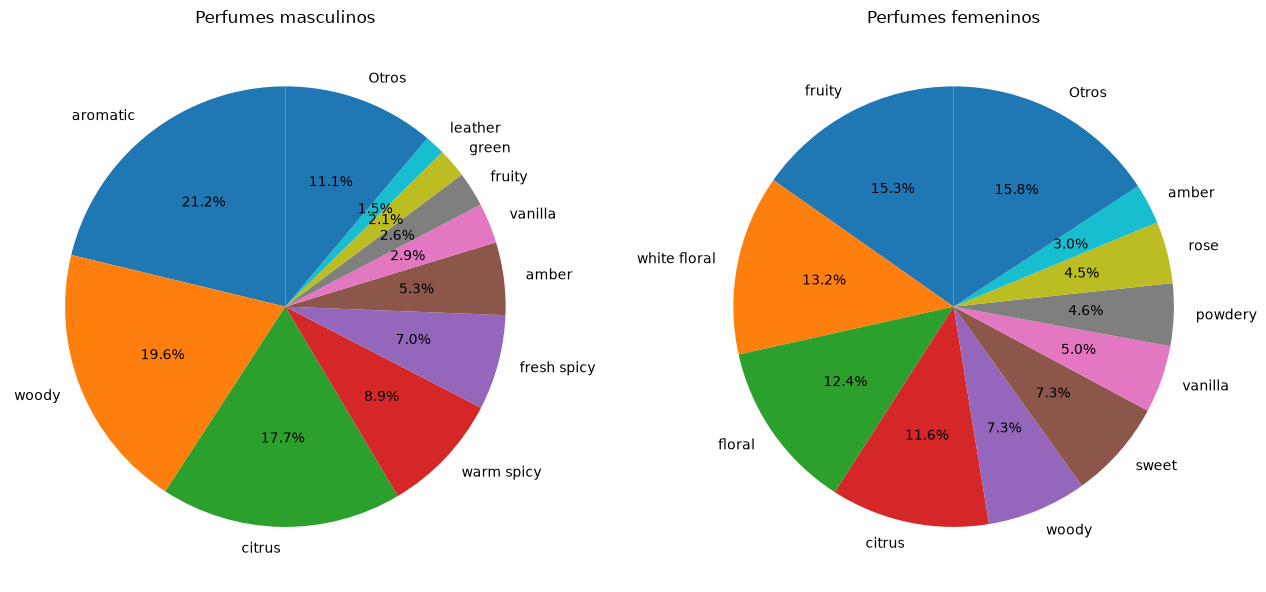

In [59]:

# obtener los 10 acordes mas frecuentes
top_hombres = hombres["mainaccord1"].value_counts().head(10)
top_mujeres = mujeres["mainaccord1"].value_counts().head(10)

# aniadir los demas acordes a "Otros"
top_hombres["Otros"] = len(hombres) - top_hombres.sum()
top_mujeres["Otros"] = len(mujeres) - top_mujeres.sum()

# dos graficos circulares
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].pie(
    top_hombres,
    labels=top_hombres.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Perfumes masculinos")

axes[1].pie(
    top_mujeres,
    labels=top_mujeres.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Perfumes femeninos")

plt.tight_layout()
plt.show()


#### Conclusión de H2

**Hipótesis parcialmente confirmada:** Los perfumes masculinos presentan principalmente acordes aromáticos (21,23 %), amaderados (19,60 %) y cítricos (17,70 %). Los especiados también aparecen, pero no son los más frecuentes.
En cambio, en los perfumes femeninos predominan los acordes frutales (15,26 %), florales blancos (13,23 %) y florales (12,45 %).

Los resultados muestran diferencias entre ambos géneros y confirman el predominio de los acordes florales y frutales en los perfumes femeninos, pero en los masculinos destacan más los aromáticos que los especiados.

***

### H3. Similitud olfativa de los perfumes unisex

**Hipótesis 3: Los perfumes unisex presentan perfiles olfativos más similares a los masculinos que a los femeninos.**

Para comprobarlo, se compara las distribuciones porcentuales de todos los acordes principales de las tres categorías.

In [91]:
unisex = df[df["Gender"] == "unisex"]

In [61]:
# calcular los porcentajes de todos los acordes
pct_hombres = hombres["mainaccord1"].value_counts(normalize=True) * 100
pct_mujeres = mujeres["mainaccord1"].value_counts(normalize=True) * 100
pct_unisex = unisex["mainaccord1"].value_counts(normalize=True) * 100

In [62]:
# tabla comparativa
comparacion_h3 = pd.DataFrame({
    "Hombres (%)": pct_hombres,
    "Mujeres (%)": pct_mujeres,
    "Unisex (%)": pct_unisex
}).fillna(0)

comparacion_h3.round(2)

,Hombres (%),Mujeres (%),Unisex (%)
mainaccord1,,,
aldehydic,0.02,0.21,0.14
almond,0.14,0.31,0.27
amber,5.33,2.96,8.70
animalic,0.04,0.01,0.19
anis,0.10,0.02,0.05
...,...,...,...
warm spicy,8.88,2.71,7.51
whiskey,0.02,0.00,0.01
white floral,0.50,13.23,5.29


Comparación de perfiles olfativos. Para facilitarlo, se compara los diez acordes más frecuentes de los perfumes unisex con los de las categorías masculina y femenina.

In [84]:
top10_acordes = pct_unisex.head(10).index
grafico_h3 = comparacion_h3.loc[top10_acordes]
grafico_h3

,Hombres (%),Mujeres (%),Unisex (%)
mainaccord1,,,
woody,19.603127,7.322433,17.420109
citrus,17.698938,11.629747,14.471291
amber,5.331730,2.962377,8.703559
warm spicy,8.879535,2.707454,7.508444
aromatic,21.226699,1.344937,5.897636
fruity,2.565644,15.260197,5.404001
white floral,0.501102,13.229606,5.287088
sweet,1.423131,7.278481,4.234866
rose,0.380838,4.544655,3.728241


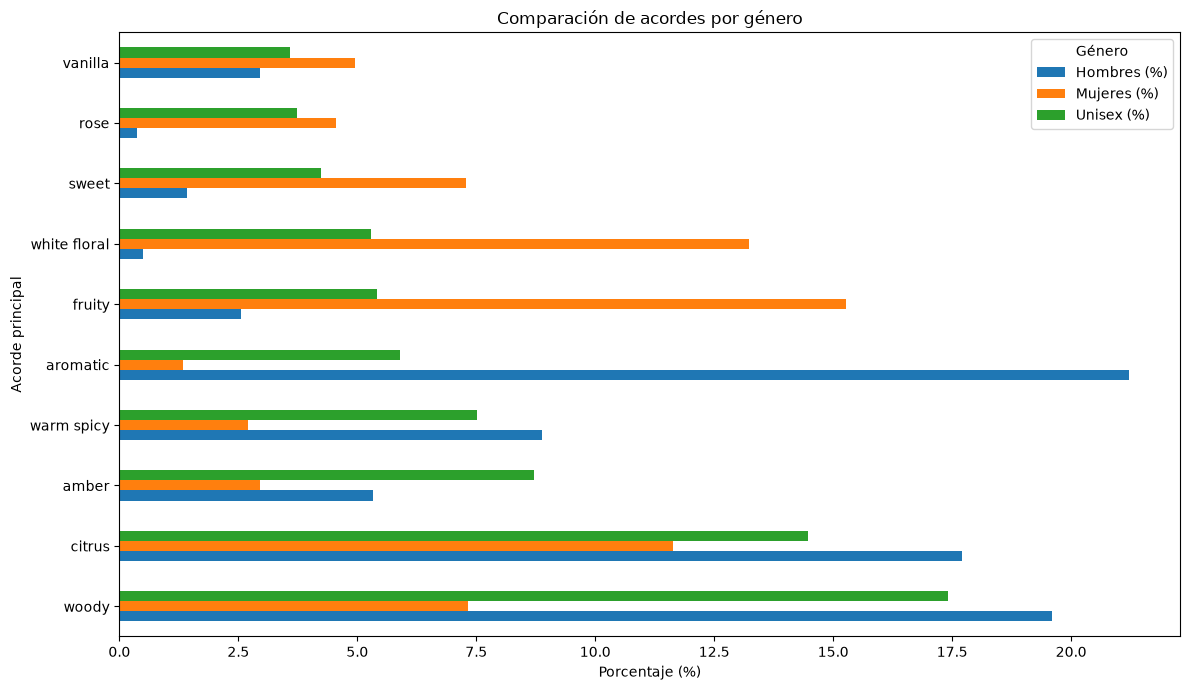

In [64]:
grafico_h3.plot.barh(
    figsize=(12, 7)
)

plt.title("Comparación de acordes por género")
plt.xlabel("Porcentaje (%)")
plt.ylabel("Acorde principal")
plt.legend(title="Género")

plt.tight_layout()
plt.show()

Similitud entre perfiles olfativos. Para comprobar la hipótesis, se calcula la diferencia total entre los porcentajes de los acordes unisex y los de las categorías masculina y femenina.

El índice de similitud se calcula como 100 - (distancia / 2), donde la distancia es la suma de las diferencias absolutas entre los porcentajes de cada acorde. Dividir entre 2 normaliza el resultado al rango de 0 a 100, ya que la suma máxima posible de diferencias absolutas entre dos distribuciones es 200.

In [65]:
# diferencia entre unisex y hombres
diferencia_hombres = (
    comparacion_h3["Unisex (%)"] - comparacion_h3["Hombres (%)"]
).abs().sum()

# diferencia entre unisex y mujeres
diferencia_mujeres = (
    comparacion_h3["Unisex (%)"] - comparacion_h3["Mujeres (%)"]
).abs().sum()

# convertir las diferencias en un indice de similitud
similitud_hombres = 100 - diferencia_hombres / 2
similitud_mujeres = 100 - diferencia_mujeres / 2

print("Unisex vs. hombres:", round(similitud_hombres, 2), "%")
print("Unisex vs. mujeres:", round(similitud_mujeres, 2), "%")

Unisex vs. hombres: 70.5 %
Unisex vs. mujeres: 64.0 %


Cuanto mayor es el índice de similitud, más parecidas son las distribuciones de los acordes principales.

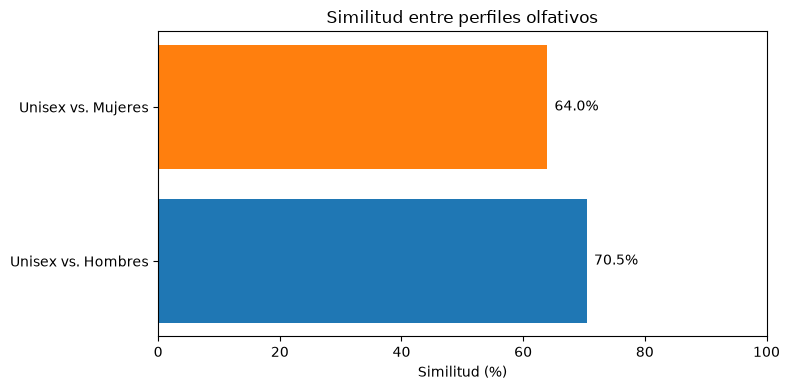

In [66]:
# grafico de comparacion
plt.figure(figsize=(8, 4))

categorias = ["Unisex vs. Hombres", "Unisex vs. Mujeres"]
similitudes = [similitud_hombres, similitud_mujeres]

barras = plt.barh(
    categorias,
    similitudes, color=plt.cm.tab10.colors)

# mostrar los porcentajes al final de las barras
plt.bar_label(barras, fmt="%.1f%%", padding=5)

plt.title("Similitud entre perfiles olfativos")
plt.xlabel("Similitud (%)")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

#### Conclusión de H3

**Hipótesis confirmada:** Los perfumes unisex presentan una mayor similitud en la distribución de sus acordes principales con los masculinos 70,5% que con los femeninos 64%.

***

### H4. País de origen de los perfumes más populares

**Hipótesis 4: Francia es el país de origen de la mayoría de los diez perfumes más populares.**

Para comprobarlo,  se identifican los diez perfumes con más valoraciones y se analiza su país de origen.

In [85]:
top10_perfumes = df.sort_values("Rating Count", ascending=False).head(10)
top10_perfumes[["Perfume", "Brand", "Country", "Gender", "Rating Count"]]

,Perfume,Brand,Country,Gender,Rating Count
12914,alien,mugler,France,women,29858
1812,angel,mugler,France,women,29722
7457,light-blue,dolce-gabbana,Italy,women,29708
17145,coco-mademoiselle,chanel,France,women,29283
2746,la-vie-est-belle,lancome,France,women,28982
9859,black-orchid,tom-ford,USA,women,26053
10579,black-opium,yves-saint-laurent,France,women,25669
16127,hypnotic-poison,dior,France,women,25173
5691,j-adore,dior,France,women,25013
8729,sauvage,dior,France,men,23727


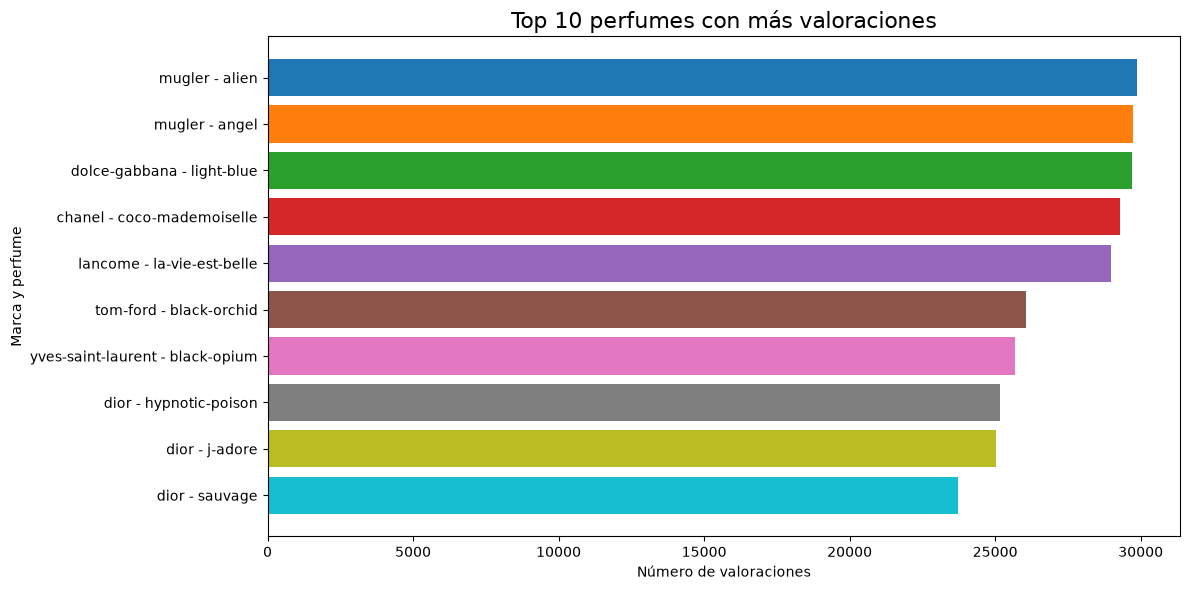

In [90]:
# 10 perfumes con mas valoraciones
top10_perfumes = df.sort_values("Rating Count", ascending=False).head(10).copy()

# unir marca y nombre del perfume
top10_perfumes["Nombre"] = top10_perfumes["Brand"] + " - " + top10_perfumes["Perfume"]

# grafico
plt.figure(figsize=(12, 6))

plt.barh(top10_perfumes["Nombre"], top10_perfumes["Rating Count"], color=plt.cm.tab10.colors)

plt.title("Top 10 perfumes con más valoraciones", fontsize=16)
plt.xlabel("Número de valoraciones")
plt.ylabel("Marca y perfume")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [88]:
# pais de estos 10 perfumes
paises_top10_perfumes = top10_perfumes["Country"].value_counts()
paises_top10_perfumes

Country
France    8
Italy     1
USA       1
Name: count, dtype: int64

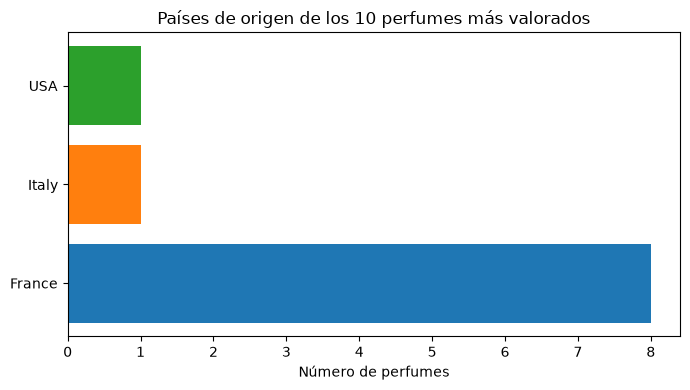

In [92]:
plt.figure(figsize=(7, 4))

plt.barh(paises_top10.index, paises_top10.values, color=plt.cm.tab10.colors)

plt.title("Países de origen de los 10 perfumes más valorados")
plt.xlabel("Número de perfumes")

plt.tight_layout()
plt.show()

#### Conclusión de H4

**Hipótesis parcialmente confirmada**: Francia domina con 8 de los 10 perfumes más valorados, pero no es la única procedencia: Italia y Estados Unidos también aparecen entre los más populares.

***

### Conclusión
De las 4 hipótesis planteadas:
- 2 confirmadas: H1 y H3.
- 2 parcialmente confirmada: H2 y H4.
- 0 no confirmadas.

Los resultados muestran un mercado con clara diferenciación por género: más variedad femenina (H1) y perfiles olfativos distintos (H2). Los perfumes unisex se sitúan más cerca del perfil masculino que del femenino (H3), lo que sugiere que su formulación parte históricamente de la perfumería masculina. Francia mantiene un protagonismo dominante entre los más populares, aunque no exclusivo (H4). 